# BRASA · Cuaderno temporal de delimitación

Este cuaderno muestra los resultados intermedios del **mismo motor que usa FastAPI**. Cambia `SCENE` y ejecuta todas las celdas. No modifica las imágenes originales.

Entrada: composiciones JPEG de visualización. Los canales no son reflectancias calibradas. Las regiones representan evidencia de afectación, no fuego confirmado ni área geográfica medida.

Escala declarada: **20 m por píxel original cuadrado**. Las hectáreas y metros se estiman compensando la reducción de tamaño; no hay coordenadas geográficas en los JPEG.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if (ROOT / "backend").is_dir():
    BACKEND = ROOT / "backend"
elif (ROOT / "processing").is_dir():
    BACKEND = ROOT
else:
    raise RuntimeError("Abre el cuaderno desde la raíz del proyecto o desde backend.")
sys.path.insert(0, str(BACKEND))
from processing import analyze, SegmentationConfig
from processing.io import read_rgb
from processing.evaluation import evaluate_mask
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})

SCENE = "Niebla"  # Alternativas: "La_Mierla", "Madrid-Avila"
CONFIG = SegmentationConfig(max_side=1536, sensitivity=0.5, refine=True, pixel_size_m=20)
folder = BACKEND / "images" / SCENE
swir, original_size = read_rgb(folder / "image_SWIR.jpg")
visible, visible_size = read_rgb(folder / "image_True_color.jpg")
assert original_size == visible_size, "Las dimensiones originales no coinciden."
result = analyze(swir, visible, CONFIG, original_size=original_size)
print("Escena:", SCENE)
print("Tamaño original:", original_size)
print("Resolución inicial:", result["coarse_size"])
print("Resolución final:", result["analysis_size"])
print("Configuración:", json.dumps(CONFIG.to_dict(), indent=2))

Escena: Niebla
Tamaño original: (2500, 1546)
Resolución inicial: {'width': 1536, 'height': 950}
Resolución final: {'width': 2500, 'height': 1546}
Configuración: {
  "max_side": 1536,
  "sensitivity": 0.5,
  "min_area_fraction": 0.00012,
  "closing_radius": 2,
  "max_hole_fraction": 0.00015,
  "simplify_pixels": 1.5,
  "refine": true,
  "pixel_size_m": 20
}


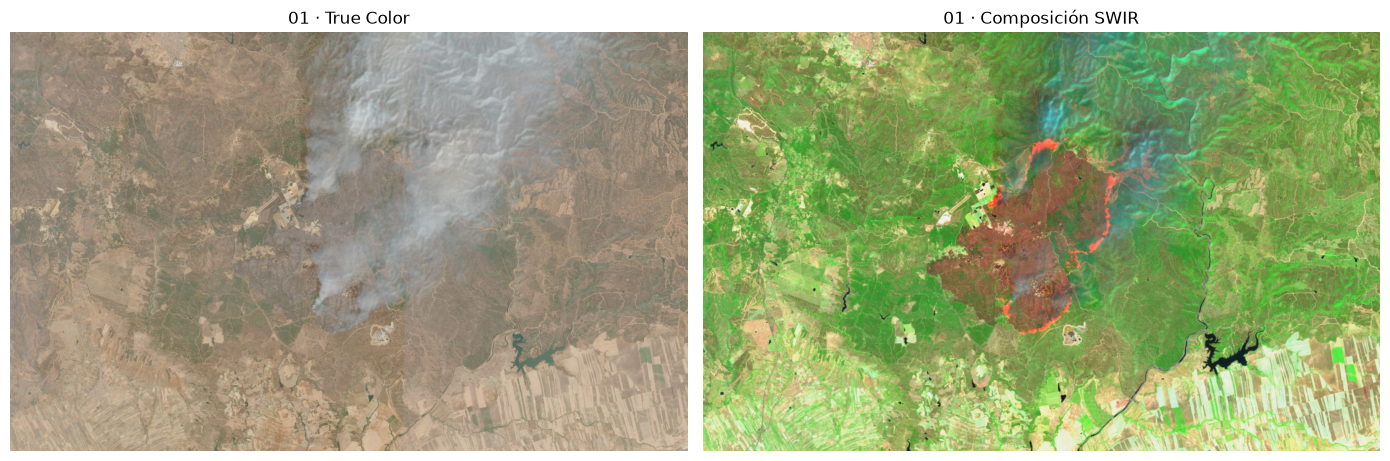

{
  "status": "usable",
  "uninformative": false,
  "checks": [
    {
      "id": "information",
      "label": "Información de la composición",
      "status": "ok",
      "detail": "La composición contiene variación espacial utilizable."
    },
    {
      "id": "alignment",
      "label": "Correspondencia espacial",
      "status": "ok",
      "detail": "Coincidencia geométrica: 182 puntos concordantes."
    },
    {
      "id": "coverage",
      "label": "Cobertura de ambas imágenes",
      "status": "ok",
      "detail": "100.0% del encuadre tiene datos no negros en ambas composiciones."
    },
    {
      "id": "clipping",
      "label": "Saturación del canal rojo",
      "status": "ok",
      "detail": "0.06% de píxeles alcanza el límite de visualización; en esa zona se pierde información radiométrica."
    },
    {
      "id": "observation",
      "label": "Superficie observable",
      "status": "ok",
      "detail": "8.4% de incertidumbre visual o falta de datos. Las zonas oc

In [2]:
def show(images, titles, cmaps=None, figsize=None):
    fig, axes = plt.subplots(1, len(images), figsize=figsize or (7 * len(images), 5), squeeze=False)
    for index, (image, title) in enumerate(zip(images, titles)):
        cmap = cmaps[index] if cmaps else None
        artist = axes[0, index].imshow(image, cmap=cmap)
        axes[0, index].set_title(title)
        axes[0, index].axis("off")
        if cmap and image.dtype != bool:
            fig.colorbar(artist, ax=axes[0, index], fraction=.03, pad=.02)
    plt.tight_layout()
    plt.show()

show([visible, swir], ["01 · True Color", "01 · Composición SWIR"])
print(json.dumps(result["quality"], ensure_ascii=False, indent=2))

## 02 · Características de color

`RG = (R-G)/(R+G+epsilon)` expresa predominio rojo frente a verde en el JPEG. Lab separa parcialmente cromaticidad y luminosidad. Ninguna de estas imágenes constituye un índice espectral calibrado.

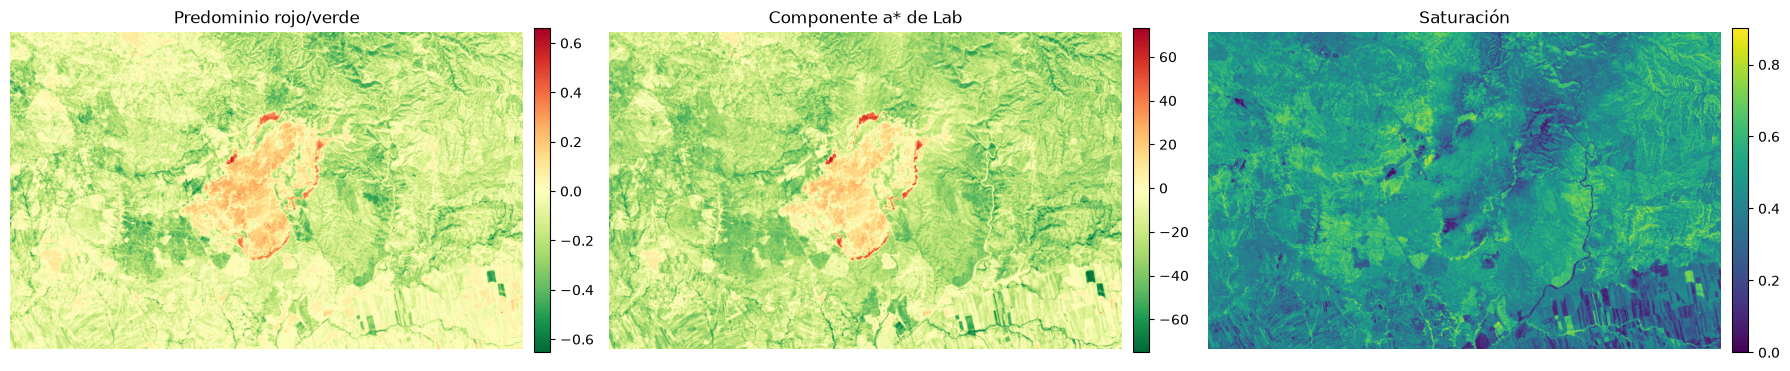

rg percentiles 5/50/95: [-0.333 -0.102  0.084]
lab_a percentiles 5/50/95: [-44.031 -22.578   3.875]
saturation percentiles 5/50/95: [0.252 0.467 0.639]


In [3]:
s = result["steps"]
show([s["rg"], s["lab_a"], s["saturation"]], ["Predominio rojo/verde", "Componente a* de Lab", "Saturación"], ["RdYlGn_r", "RdYlGn_r", "viridis"], (18, 5))
for key in ["rg", "lab_a", "saturation"]:
    print(key, "percentiles 5/50/95:", np.round(np.percentile(s[key], [5, 50, 95]), 3))

## 03 · Puntuación de evidencia y umbrales

La puntuación combina predominio rojo, Lab y saturación con escalas fijas. No se estira el histograma por escena. Es una heurística explicable; **no es una probabilidad de incendio**.

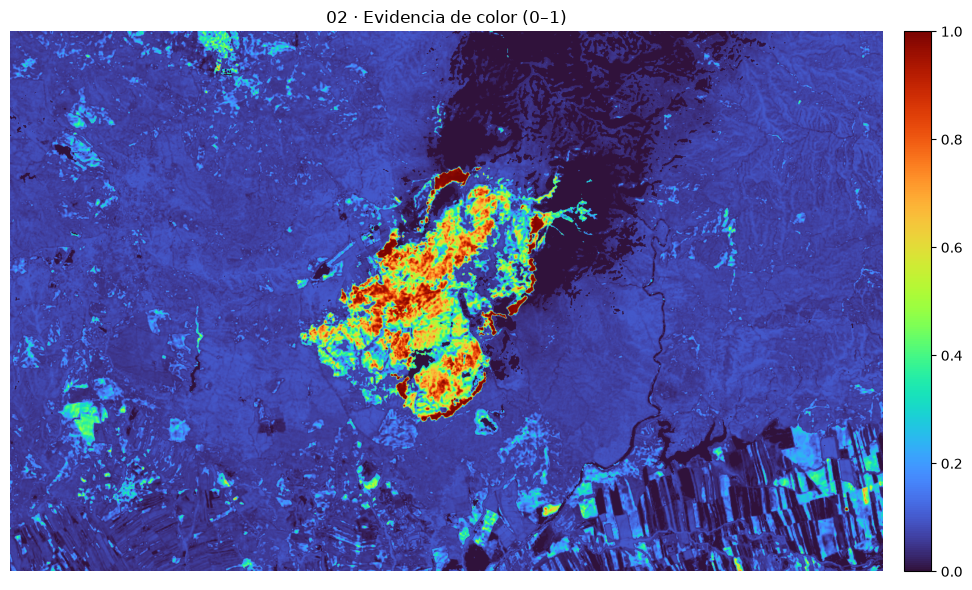

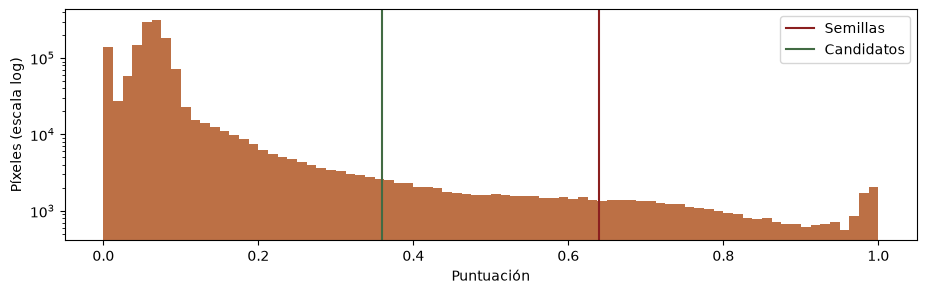

Umbral estricto: 0.64 Umbral permisivo: 0.36


In [4]:
show([s["score"]], ["02 · Evidencia de color (0–1)"], ["turbo"], (11, 6))
fig, ax = plt.subplots(figsize=(11, 3))
ax.hist(s["score"].ravel(), bins=80, color="#bc7045", log=True)
ax.axvline(s["seed_threshold"], color="#8b1f1f", label="Semillas")
ax.axvline(s["candidate_threshold"], color="#426b43", label="Candidatos")
ax.set_xlabel("Puntuación"); ax.set_ylabel("Píxeles (escala log)"); ax.legend(); plt.show()
print("Umbral estricto:", s["seed_threshold"], "Umbral permisivo:", s["candidate_threshold"])

## 04 · Semillas y candidatos

Las semillas son píxeles con evidencia fuerte. Los candidatos admiten señales más débiles. La sensibilidad desplaza ambos umbrales mediante una regla común a todas las escenas.

Las superficies muy claras o rojizas en True Color no inician regiones por sí solas: siguen siendo candidatos si se conectan con una semilla oscura. Agua y vegetación con evidencia concordante en ambas composiciones se excluyen. La incertidumbre se elimina antes del crecimiento para impedir conexiones a través del humo.

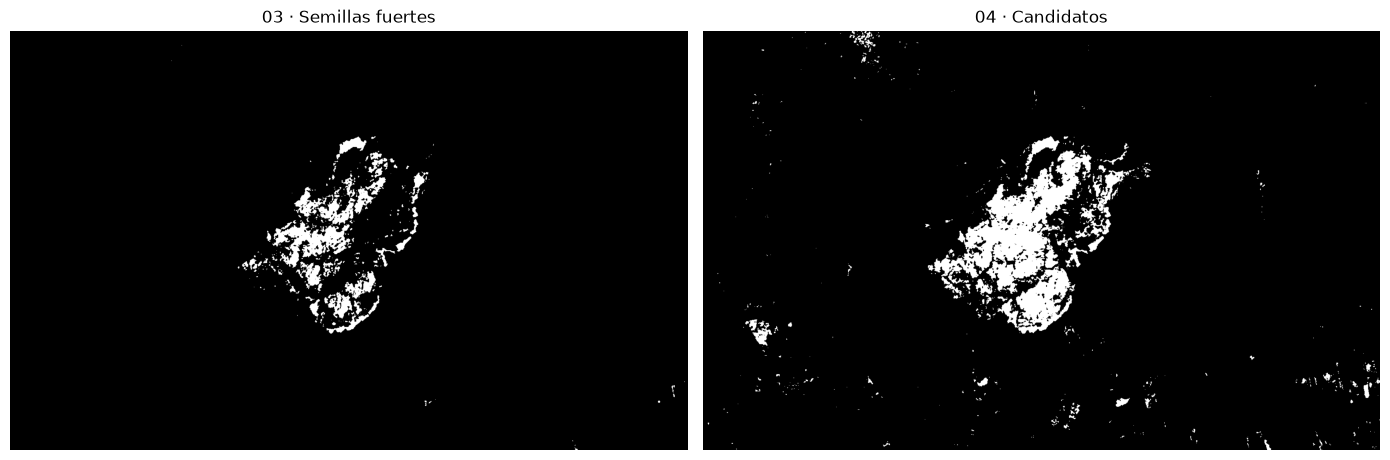

Semillas: 30092 Candidatos: 69256


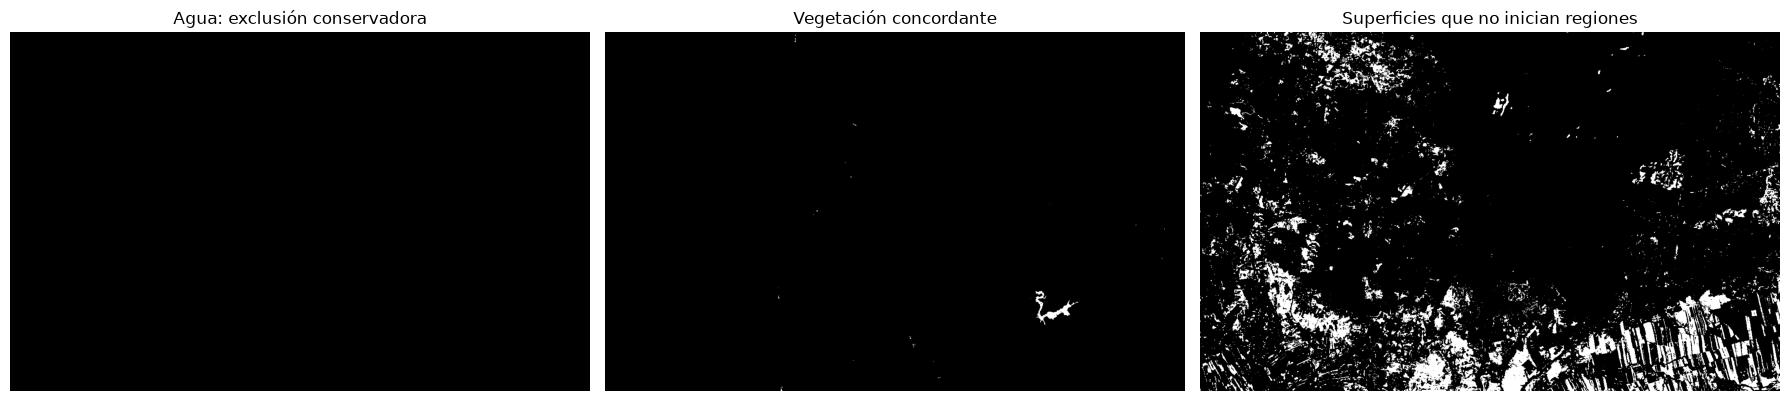

In [5]:
show([s["seeds"], s["candidates"]], ["03 · Semillas fuertes", "04 · Candidatos"], ["gray", "gray"])
print("Semillas:", int(s["seeds"].sum()), "Candidatos:", int(s["candidates"].sum()))
show([s["water"], s["vegetation"], ~s["seed_allowed"]], ["Agua: exclusión conservadora", "Vegetación concordante", "Superficies que no inician regiones"], ["gray"] * 3, (18, 5))

## 05 · Crecimiento conectado

Se conservan componentes de candidatos que contienen al menos una semilla, con conectividad de ocho. Un candidato aislado sin semillas no se incorpora.

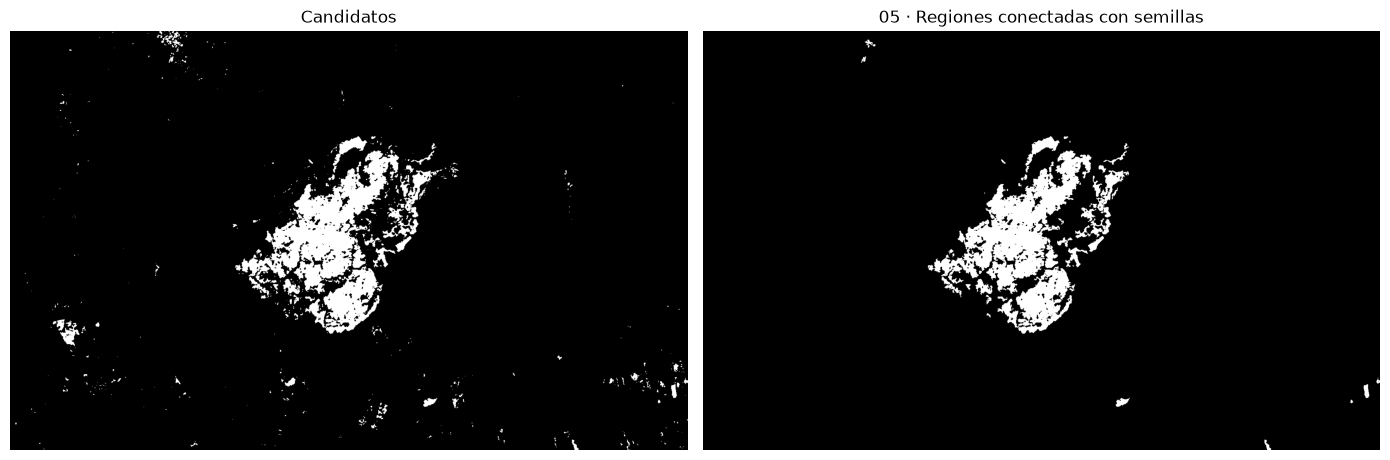

Píxeles tras reconstrucción: 61995


In [6]:
show([s["candidates"], s["grown"]], ["Candidatos", "05 · Regiones conectadas con semillas"], ["gray", "gray"])
print("Píxeles tras reconstrucción:", int(s["grown"].sum()))

## 06 · Incertidumbre y limpieza

Cierre pequeño, filtrado por tamaño y relleno de huecos limitado. Se preservan huecos grandes y zonas inciertas. La incertidumbre se estima mediante una combinación visual de brillo/saturación en True Color y color cian en SWIR; **no es una máscara de nubes validada**.

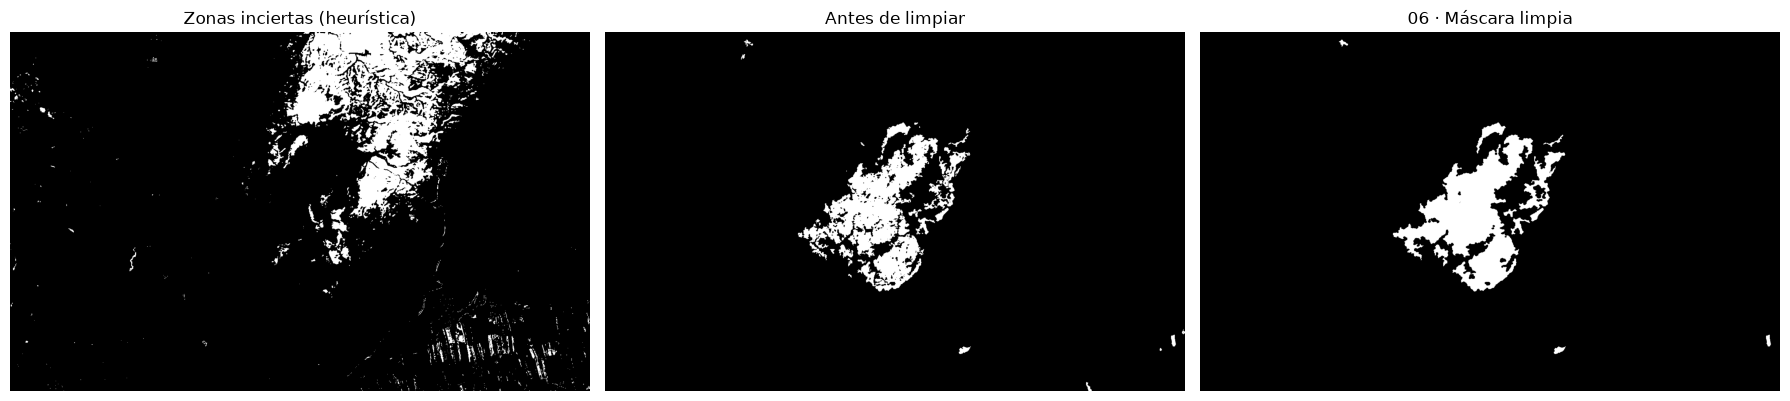

Píxeles antes: 61995 después: 68153


In [7]:
show([s["uncertain"], s["grown"], s["cleaned"]], ["Zonas inciertas (heurística)", "Antes de limpiar", "06 · Máscara limpia"], ["gray", "gray", "gray"], (18, 5))
print("Píxeles antes:", int(s["grown"].sum()), "después:", int(s["cleaned"].sum()))

## 07 · Refinamiento y perímetro

Si está activo, se examina una banda alrededor de los límites a una resolución mayor, con tamaño acotado y cálculo por bloques. Los polígonos se expresan en coordenadas de la imagen original. El perímetro reportado suma límites exteriores; los huecos se guardan por separado.

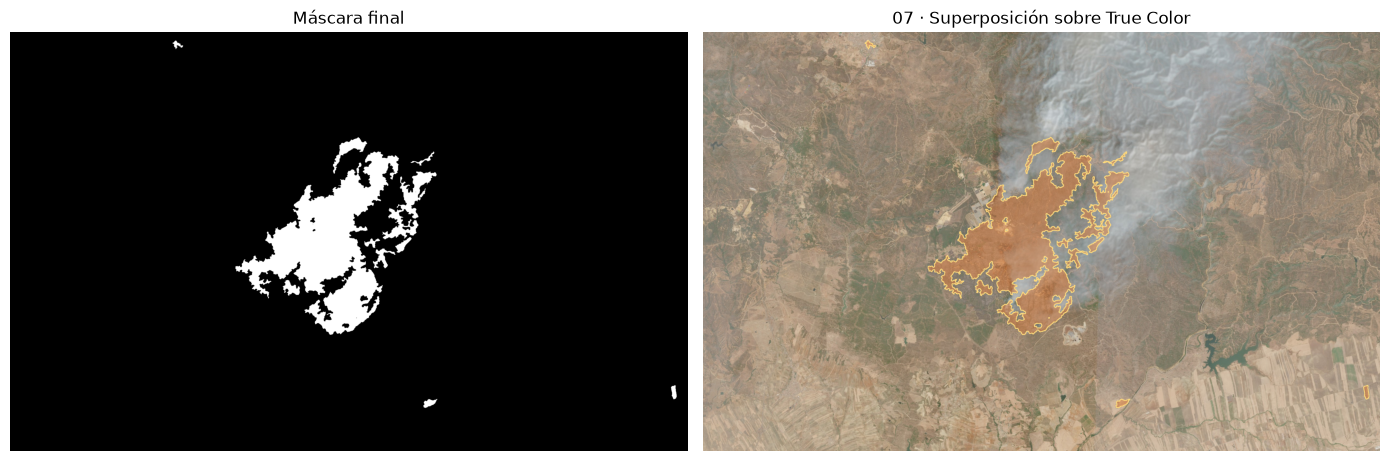

{
  "affected_analysis_pixels": 178709,
  "affected_original_pixels_estimated": 178709,
  "uncertain_analysis_pixels": 325359,
  "region_count": 11,
  "affected_percent": 4.624,
  "uncertain_percent": 8.418,
  "affected_observable_percent": 5.049,
  "perimeter_original_pixels_estimated": 10604.83,
  "affected_area_m2_estimated": 71483600.0,
  "affected_area_hectares_estimated": 7148.36,
  "perimeter_m_estimated": 212096.65,
  "processing_ms": 4154
}
Valores de etiquetas: [  0   1 255]
• Análisis de colores de un JPEG: no son reflectancias ni índices espectrales calibrados.
• Escala declarada: 20 m por píxel original cuadrado. Las medidas son estimaciones; los JPEG no contienen georreferenciación para verificar la escala ni obtener coordenadas terrestres.
• La máscara de incertidumbre es una heurística visual de humo/nube y zonas sin datos.
• El encuadre se comprueba con correspondencias geométricas cuando hay textura suficiente; no se corrigen automáticamente desplazamientos.
Mayores r

In [8]:
show([result["mask"], result["overlay"]], ["Máscara final", "07 · Superposición sobre True Color"], ["gray", None])
print(json.dumps(result["stats"], indent=2, ensure_ascii=False))
print("Valores de etiquetas:", np.unique(result["labels"]))
for warning in result["warnings"]:
    print("•", warning)
print("Mayores regiones:")
for region in result["regions"][:8]:
    print({key: region[key] for key in ["id", "area_original_pixels_estimated", "perimeter_original_pixels_estimated", "area_hectares_estimated", "perimeter_m_estimated", "bbox"]})

### Medidas con 20 m por píxel

Un píxel original equivale a 20 × 20 = **400 m² = 0,04 ha**. Para una máscara reducida, el área es `N × (ancho_original/ancho_máscara) × (alto_original/alto_máscara) × 400`. Cada segmento del contorno se escala por separado en x e y antes de multiplicar su longitud por 20. Los huecos no cuentan como superficie afectada y el perímetro mostrado suma los límites exteriores. La resolución del render debe conservar la escala declarada.

## 08 · Comparar sensibilidad

Esta comparación mide estabilidad visual y área detectada. No establece cuál es la sensibilidad correcta sin una referencia independiente.

Sensibilidad 0.3: 4.36% del encuadre, 8 regiones


Sensibilidad 0.5: 4.84% del encuadre, 10 regiones


Sensibilidad 0.7: 5.28% del encuadre, 12 regiones


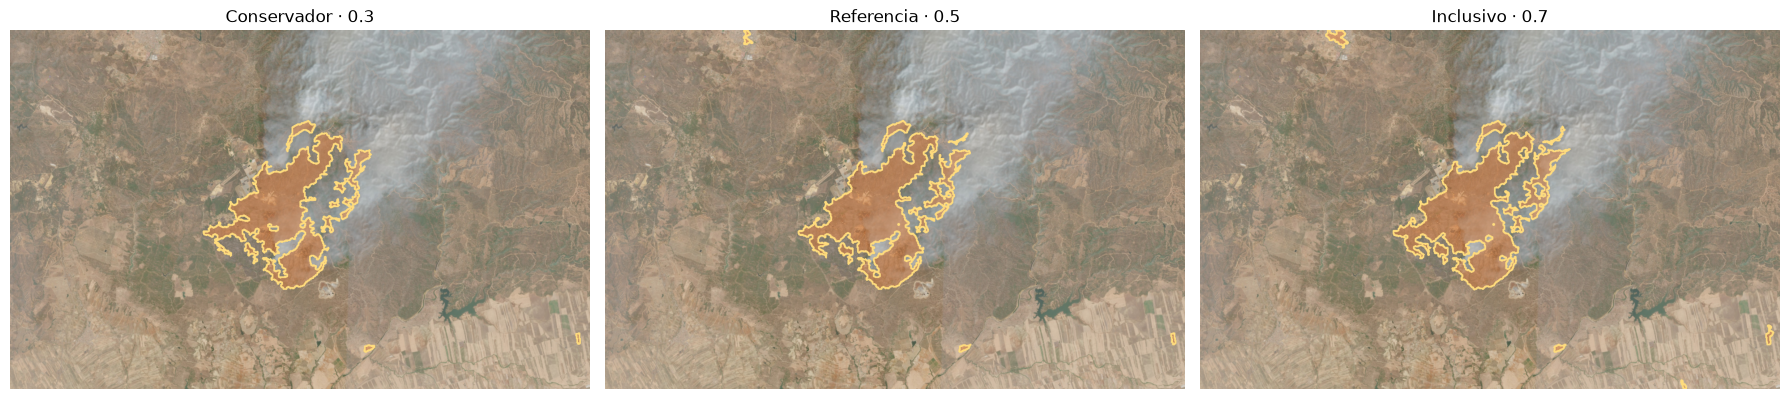

In [9]:
variants = []
for sensitivity in [.3, .5, .7]:
    variant = analyze(swir, visible, SegmentationConfig(max_side=1024, sensitivity=sensitivity, refine=False), original_size=original_size)
    variants.append(variant)
    print(f"Sensibilidad {sensitivity:.1f}: {variant['stats']['affected_percent']:.2f}% del encuadre, {variant['stats']['region_count']} regiones")
show([v["overlay"] for v in variants], ["Conservador · 0.3", "Referencia · 0.5", "Inclusivo · 0.7"], figsize=(18, 5))

## 09 · Las tres escenas con una configuración común

Revisar agricultura, agua, bordes bajo humo y pequeños falsos positivos. Los porcentajes son fracciones del encuadre, no estimaciones de exactitud.

Niebla {"affected_analysis_pixels": 31355, "affected_original_pixels_estimated": 186962, "uncertain_analysis_pixels": 53997, "region_count": 10, "affected_percent": 4.837, "uncertain_percent": 8.33, "affected_observable_percent": 5.277, "perimeter_original_pixels_estimated": 8473.3, "affected_area_m2_estimated": 74784678.0, "affected_area_hectares_estimated": 7478.468, "perimeter_m_estimated": 169466.08, "processing_ms": 315}


La_Mierla {"affected_analysis_pixels": 63065, "affected_original_pixels_estimated": 376040, "uncertain_analysis_pixels": 17947, "region_count": 12, "affected_percent": 9.729, "uncertain_percent": 2.769, "affected_observable_percent": 10.006, "perimeter_original_pixels_estimated": 11133.21, "affected_area_m2_estimated": 150416064.99, "affected_area_hectares_estimated": 15041.606, "perimeter_m_estimated": 222664.26, "processing_ms": 344}


Madrid-Avila {"affected_analysis_pixels": 25676, "affected_original_pixels_estimated": 2415528, "uncertain_analysis_pixels": 48230, "region_count": 14, "affected_percent": 3.961, "uncertain_percent": 7.441, "affected_observable_percent": 4.28, "perimeter_original_pixels_estimated": 43322.84, "affected_area_m2_estimated": 966211133.66, "affected_area_hectares_estimated": 96621.113, "perimeter_m_estimated": 866456.7, "processing_ms": 399}


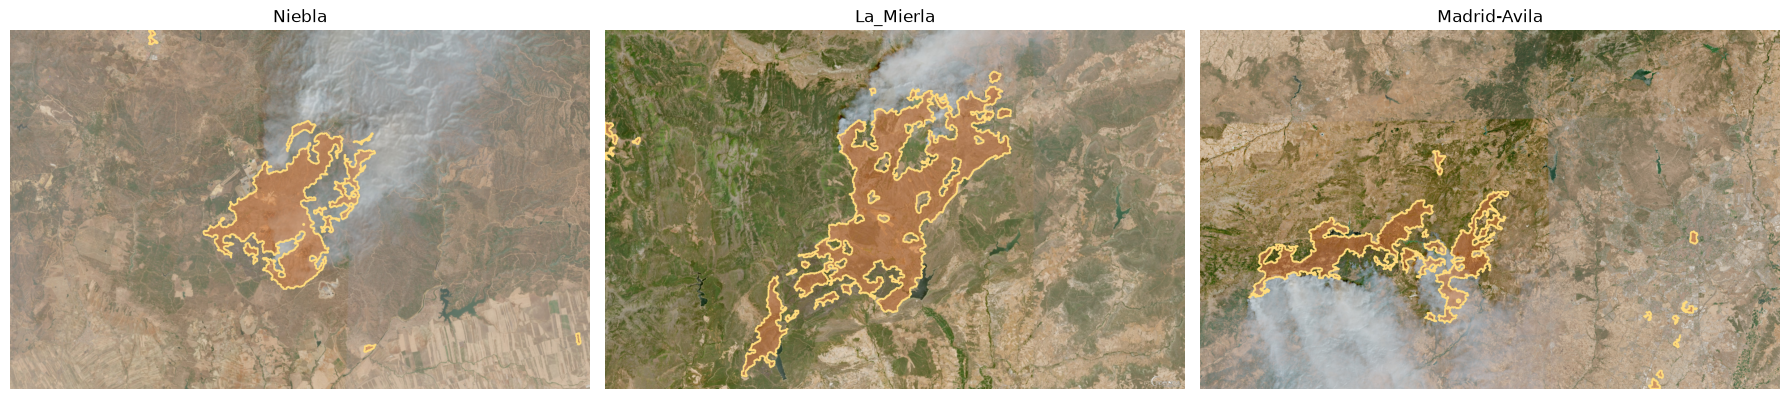

In [10]:
comparisons = []
for scene in ["Niebla", "La_Mierla", "Madrid-Avila"]:
    path = BACKEND / "images" / scene
    x, size = read_rgb(path / "image_SWIR.jpg")
    y, _ = read_rgb(path / "image_True_color.jpg")
    r = analyze(x, y, SegmentationConfig(max_side=1024, refine=False), original_size=size)
    comparisons.append((scene, r["overlay"]))
    print(scene, json.dumps(r["stats"], ensure_ascii=False))
    del x, y, r
show([r for _, r in comparisons], [name for name, _ in comparisons], figsize=(18, 5))

## 10 · Evaluación opcional con referencia manual

Guarda una máscara independiente `backend/references/<SCENE>.png`: 0=fondo, 1=afectado, 255=ignorar. Debe tener exactamente la cuadrícula de la máscara final mostrada arriba. Una anotación en resolución original debe remuestrearse conscientemente y revisarse antes de evaluar. Las métricas no se calculan contra las propias semillas ni contra Wildfires.

In [11]:
reference_path = BACKEND / "references" / f"{SCENE}.png"
if reference_path.exists():
    from PIL import Image
    reference = np.array(Image.open(reference_path))
    if reference.ndim != 2 or not set(np.unique(reference)).issubset({0, 1, 255}):
        raise ValueError("La referencia debe ser de un canal y contener solo 0, 1 y 255.")
    print(json.dumps(evaluate_mask(result["mask"].astype(np.uint8), reference, tolerance=2), indent=2))
else:
    print("No hay referencia manual independiente. No se reporta IoU ni Dice.")
    print("Ruta esperada:", reference_path)
    print("Cuadrícula requerida:", result["analysis_size"])

No hay referencia manual independiente. No se reporta IoU ni Dice.
Ruta esperada: C:\Users\javie\Desktop\IndraThon\backend\references\Niebla.png
Cuadrícula requerida: {'width': 2500, 'height': 1546}


## 11 · Exportación local opcional

La siguiente celda guarda las máscaras, la superposición y la geometría dentro de `backend/results/notebook_<SCENE>`. Las imágenes de entrada se conservan intactas.

In [12]:
EXPORT = False  # Actívalo para guardar estos resultados.
if EXPORT:
    from processing.io import write_rgb, write_mask
    output = BACKEND / "results" / f"notebook_{SCENE}"
    output.mkdir(parents=True, exist_ok=True)
    write_rgb(output / "overlay.jpg", result["overlay"])
    write_mask(output / "mask.png", result["mask"] * 255)
    write_mask(output / "labels.png", result["labels"])
    (output / "regions.json").write_text(json.dumps({"coordinate_system": "image_pixels", "original_size": result["original_size"], "regions": result["regions"]}, ensure_ascii=False), encoding="utf-8")
    print("Guardado en:", output)
else:
    print("Exportación desactivada. Los gráficos anteriores ya están incluidos en el cuaderno ejecutado.")

Exportación desactivada. Los gráficos anteriores ya están incluidos en el cuaderno ejecutado.
